# Section 3 - Export Side of AI-Related Trade
Generates: figures/ai-exports-index, ai-exports-by-country, ai-exports-by-country-category.
**Run after 06** - appends to tables/ai-trade-results.tex.


In [1]:
import pandas as pd             # data package
import matplotlib.pyplot as plt # graphics 
import datetime as dt
import numpy as np
import os

In [2]:
figfile = '../paper/figures/'
texfile = '../paper/tables/ai-trade-results.tex'

# The domestic/re-export (DF) breakout parquets are produced by the sister
# us-exports-hs10 repo, which has moved between drives. Take the first
# location that actually has the files rather than hardcoding one path.
DF_DIR_CANDIDATES = [
    '../data-input',                                    # local copy, if one is ever made
    r'c:\heroku\us-exports-hs10\data\exports-hs10-DF',  # current location
    '../../us-exports-hs10/data/exports-hs10-DF',       # old c:\github location
]

DF_DIR = next((p for p in DF_DIR_CANDIDATES
               if os.path.exists(os.path.join(p, 'TOTALexports-combined-DF.parquet'))), None)

if DF_DIR is None:
    raise FileNotFoundError(
        'TOTALexports-combined-DF.parquet not found in any of: '
        + ', '.join(DF_DIR_CANDIDATES))

print('DF data directory:', DF_DIR)


DF data directory: ../data-input


In [3]:
matlist = pd.read_csv('../data-input/hs10_classification_imports_exports.csv')

# matlist = pd.read_csv('hs10_datacenter_relevance.csv')

# Convert to category
matlist['relevance'] = matlist['relevance'].astype('category')

# Or specify order if needed (e.g., for sorting/comparisons)
matlist['relevance'] = pd.Categorical(
    matlist['relevance'], 
    categories=['Low', 'Medium', 'High'], 
    ordered=True
)

matlist['primary_category'] = matlist['primary_category'].astype('category')

matlist.rename(columns={'hs10_code': 'HS10'}, inplace=True)

print(matlist["relevance"].value_counts().reindex(["Low", "Medium", "High"]).to_string())

relevance
Low       20023
Medium     3265
High        829


In [4]:
df = pd.read_parquet('../data-input/TOTALexports-combined.parquet')

df.rename(columns={'E_COMMODITY': 'HS10'}, inplace=True)

df["HS2"] = df["HS10"].str[0:2]
df["HS4"] = df["HS10"].str[0:4]

df["HS10"] = df["HS10"].astype('int64')

df.time = pd.to_datetime(df.time, format="%Y-%m")

df["exports"] = df["ALL_VAL_MO"].astype(float)

# df["duty"] = df["CAL_DUT_MO"].astype(float)

df.rename({"E_COMMODITY_SDESC": "short_description"}, axis = 1, inplace= True)

# # Remove volatile/special HS2 categories
# # These categories have prices that are either:
# # - Extremely volatile (oil, precious metals)
# # - Lumpy/irregular (aircraft)
# # - Unreliable/special (pharmaceuticals, special provisions)
excluded_hs2 = ["27", "71", "98", "99"]
df = df[~df["HS2"].isin(excluded_hs2)]

In [5]:
# Merge Relevance category from matlist onto df
df = df.merge(matlist[['HS10', 'relevance', 'primary_category', "reasoning"	]], on='HS10', how='left')

In [6]:
grp = df.groupby(['relevance', 'time'], observed=True)

grp_sum = grp[['exports']].sum().reset_index()

grp = df.groupby(['time'], observed=True)

grp_total = grp[['exports']].sum().reset_index()

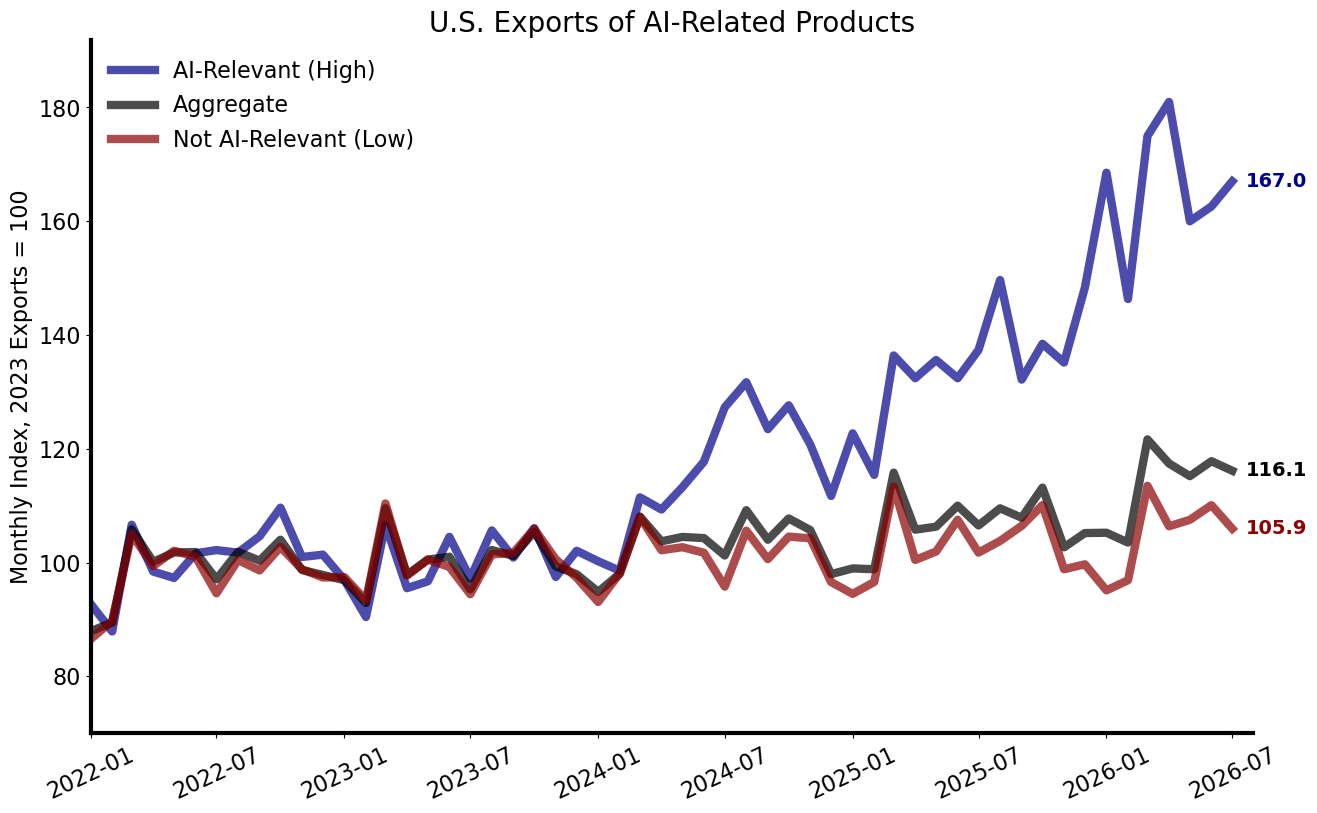

In [7]:
fig, ax = plt.subplots(figsize = (15,9))

foo = grp_sum[grp_sum['relevance']=='High'].copy()
foo.set_index('time', inplace=True)
ax.plot(foo.index, 100*(12*foo["exports"] / foo["exports"].loc["2023"].sum()) , 
        color = "darkblue", alpha = 0.7, linewidth = 6, label='AI-Relevant (High)')

foo2 = grp_total.copy()
foo2.set_index('time', inplace=True)
ax.plot(foo2.index, 100*(12*foo2["exports"] / foo2["exports"].loc["2023"].sum()) ,
         color = "black", alpha = 0.7, linewidth = 6, label='Aggregate')

foo3 = grp_sum[grp_sum['relevance']=='Low'].copy()
foo3.set_index('time', inplace=True)
ax.plot(foo3.index, 100*(12*foo3["exports"] / foo3["exports"].loc["2023"].sum()) ,
         color = "darkred", alpha = 0.7, linewidth = 6, label='Not AI-Relevant (Low)')

# Add annotations for last observations
last_date_ai = foo.index[-1]
last_value_ai = 100*(12*foo["exports"].iloc[-1] / foo["exports"].loc["2023"].sum())
ax.annotate(f'{last_value_ai:.1f}', 
            xy=(last_date_ai, last_value_ai),
            xytext=(10, 0), textcoords='offset points',
            fontsize=14, fontweight='bold', color='darkblue',
            va='center')

last_date_agg = foo2.index[-1]
last_value_agg = 100*(12*foo2["exports"].iloc[-1] / foo2["exports"].loc["2023"].sum())
ax.annotate(f'{last_value_agg:.1f}', 
            xy=(last_date_agg, last_value_agg),
            xytext=(10, 0), textcoords='offset points',
            fontsize=14, fontweight='bold', color='black',
            va='center')

last_date_not_ai = foo3.index[-1]
last_value_not_ai = 100*(12*foo3["exports"].iloc[-1] / foo3["exports"].loc["2023"].sum())
ax.annotate(f'{last_value_not_ai:.1f}', 
            xy=(last_date_not_ai, last_value_not_ai),
            xytext=(10, 0), textcoords='offset points',
            fontsize=14, fontweight='bold', color='darkred',
            va='center')

ax.set_title("U.S. Exports of AI-Related Products", fontsize = 20)

ax.set_xlim([dt.datetime(2022,1,1), last_date_not_ai + pd.DateOffset(days=30)])

ymax_idx = (100*(12*foo["exports"] / foo["exports"].loc["2023"].sum())).max()
ax.set_ylim(70, max(180, ymax_idx * 1.06))

ax.tick_params(axis='x', labelsize=16, rotation=25)
ax.tick_params(axis='y', labelsize=16)

ax.set_ylabel("Monthly Index, 2023 Exports = 100", fontsize=16)

ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.spines["left"].set_linewidth(3)
ax.spines["bottom"].set_linewidth(3)

ax.legend(
    fontsize=16,
    frameon=False,
    loc='upper left',
    ncol=1
)

plt.savefig(figfile + 'ai-exports-index.png', bbox_inches='tight')
plt.savefig(figfile + 'ai-exports-index.pdf', bbox_inches='tight')
plt.show()

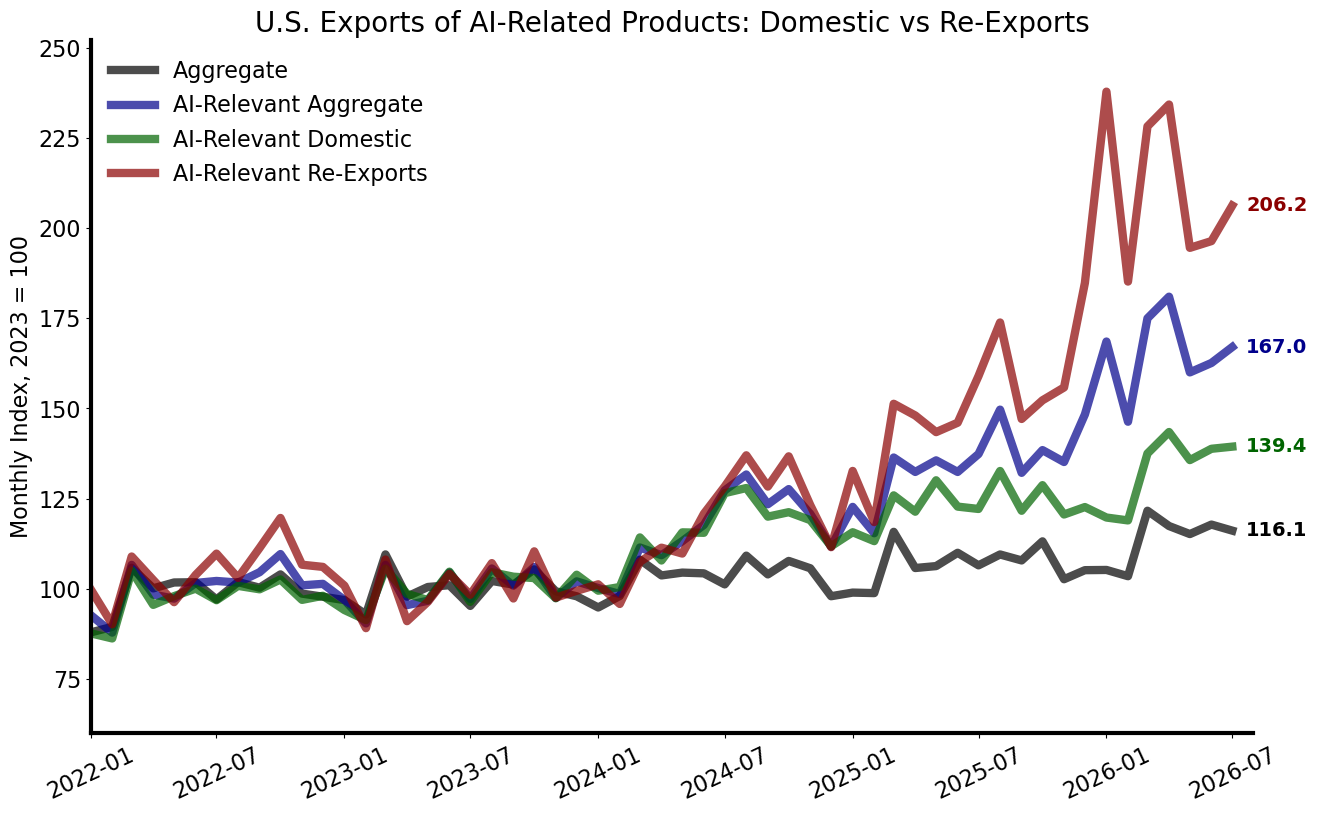

In [8]:
# Same time-series plot as cell 7, but split the AI-Relevant (High) line into
# Domestic Exports vs Re-Exports (plus the AI-Relevant Aggregate). The overall
# Aggregate (all products) line from cell 7 is kept for reference.
# Uses the DF (domestic/foreign) breakout from
# <DF_DIR>/TOTALexports-combined-DF.parquet (DF_DIR resolved in the setup cell).

df_DF = pd.read_parquet(os.path.join(DF_DIR, 'TOTALexports-combined-DF.parquet'))

df_DF.rename(columns={'E_COMMODITY': 'HS10'}, inplace=True)
df_DF["HS10"] = df_DF["HS10"].astype(str).str.zfill(10)
df_DF["HS2"]  = df_DF["HS10"].str[0:2]
df_DF["HS10"] = df_DF["HS10"].astype('int64')
df_DF["time"] = pd.to_datetime(df_DF["time"], format="%Y-%m")
df_DF["exports"] = df_DF["ALL_VAL_MO"].astype(float)

# Same HS2 exclusions as the main exports panel
df_DF = df_DF[~df_DF["HS2"].isin(excluded_hs2)]

# Merge AI relevance
df_DF = df_DF.merge(matlist[['HS10', 'relevance', 'primary_category']], on='HS10', how='left')

# AI-High split by export_type
df_DF_high = df_DF[df_DF['relevance'] == 'High']
grp_DF_high = (df_DF_high.groupby(['time', 'export_type'], observed=True)['exports']
                         .sum()
                         .unstack('export_type', fill_value=0))

# Overall aggregate (all relevance) — total exports across all products,
# matches the black "Aggregate" line in cell 7.
grp_overall = (df_DF[df_DF['export_type'] == 'Total Exports']
               .groupby('time', observed=True)['exports'].sum())

fig, ax = plt.subplots(figsize=(15, 9))

series_specs = [
    # (series,                    label,                       color)
    (grp_overall,                  'Aggregate',                 'black'),
    (grp_DF_high['Total Exports'], 'AI-Relevant Aggregate',     'darkblue'),
    (grp_DF_high['Domestic Exports'], 'AI-Relevant Domestic',   'darkgreen'),
    (grp_DF_high['Re-Exports'],    'AI-Relevant Re-Exports',    '#8B0000'),
]

for s, label, color in series_specs:
    base_2023 = s.loc["2023"].sum()
    idx = 100 * (12 * s / base_2023)
    ax.plot(idx.index, idx.values,
            color=color, alpha=0.7, linewidth=6, label=label)

    last_date = idx.index[-1]
    last_val  = idx.iloc[-1]
    ax.annotate(f'{last_val:.1f}',
                xy=(last_date, last_val),
                xytext=(10, 0), textcoords='offset points',
                fontsize=14, fontweight='bold', color=color,
                va='center')

ax.set_title("U.S. Exports of AI-Related Products: Domestic vs Re-Exports", fontsize=20)

ax.set_xlim([dt.datetime(2022, 1, 1), last_date + pd.DateOffset(days=30)])
ymax_idx = max((100 * (12 * s / s.loc["2023"].sum())).max() for s, _, _ in series_specs)
ax.set_ylim(60, max(240, ymax_idx * 1.06))

ax.tick_params(axis='x', labelsize=16, rotation=25)
ax.tick_params(axis='y', labelsize=16)

ax.set_ylabel("Monthly Index, 2023 = 100", fontsize=16)

ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.spines["left"].set_linewidth(3)
ax.spines["bottom"].set_linewidth(3)

ax.legend(fontsize=16, frameon=False, loc='upper left', ncol=1)

plt.savefig(figfile + 'ai-exports-index-DF.png', bbox_inches='tight')
plt.savefig(figfile + 'ai-exports-index-DF.pdf', bbox_inches='tight')
plt.show()


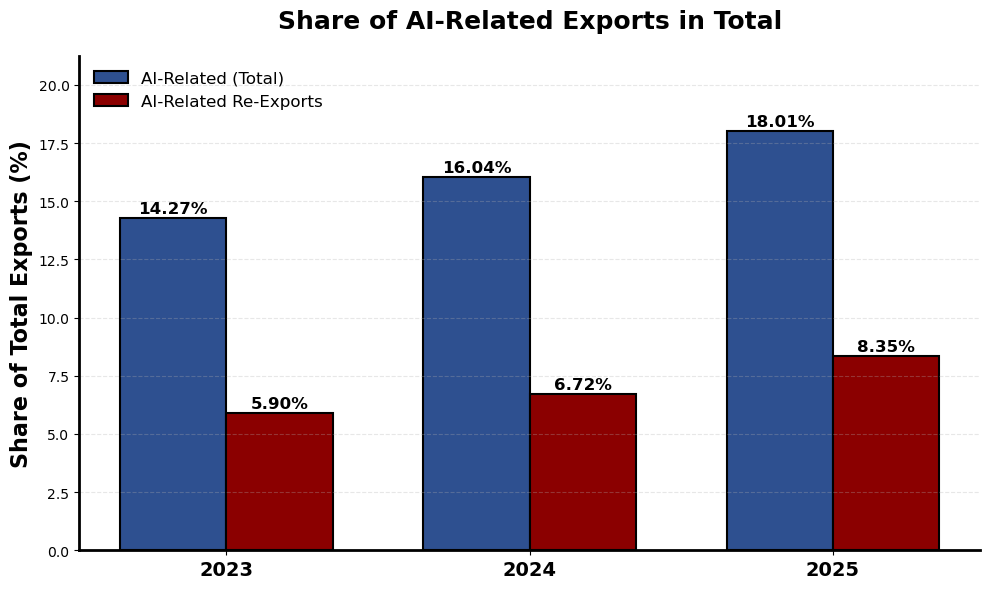


AI Trade Share (Total / Re-Exports):
  2023: total 14.27%  |  re-exports 5.90%
  2024: total 16.04%  |  re-exports 6.72%
  2025: total 18.01%  |  re-exports 8.35%

Growth in total AI share:      3.74 pp
Growth in AI re-export share:  2.45 pp


In [9]:
# Calculate AI trade share and AI re-export share for each year (2023-2025)
years = [2023, 2024, 2025]
ai_shares = []
ai_reexport_shares = []

foo = grp_sum[grp_sum['relevance']=='High'].copy().set_index("time")
df_indexed = df.set_index("time")  # local view â€” does not mutate df

# AI-High re-exports series (from the DF breakout in the cell above)
reexports_series = grp_DF_high['Re-Exports']

for year in years:
    year_str = str(year)
    total_trade = df_indexed.exports.loc[year_str].sum()
    ai_trade    = foo.exports.loc[year_str].sum()
    ai_reexp    = reexports_series.loc[year_str].sum()
    ai_shares.append((ai_trade / total_trade) * 100)
    ai_reexport_shares.append((ai_reexp / total_trade) * 100)

# Grouped bar chart: total AI share (blue) + AI re-export share (dark red)
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(years))
width = 0.35

bars_total = ax.bar(
    x - width/2, ai_shares, width,
    color='#2E5090', edgecolor='black', linewidth=1.5,
    label='AI-Related (Total)'
)
bars_re = ax.bar(
    x + width/2, ai_reexport_shares, width,
    color='#8B0000', edgecolor='black', linewidth=1.5,
    label='AI-Related Re-Exports'
)

# Value labels on bars
for bars in [bars_total, bars_re]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.1, f'{h:.2f}%',
                ha='center', va='bottom', fontsize=12, fontweight='bold')

# Formatting
ax.set_ylabel('Share of Total Exports (%)', fontsize=16, fontweight='bold')
ax.set_title('Share of AI-Related Exports in Total', fontsize=18, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(years)
ax.set_ylim(0, max(ai_shares) * 1.18)
ax.grid(axis='y', alpha=0.3, linestyle='--')

ax.tick_params(axis='x', labelsize=14)
for label in ax.get_xticklabels():
    label.set_fontweight('bold')

ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.spines["left"].set_linewidth(2)
ax.spines["bottom"].set_linewidth(2)

ax.legend(fontsize=12, frameon=False, loc='upper left')

plt.tight_layout()
plt.savefig(figfile + 'ai-exports-share.png', bbox_inches='tight')
plt.savefig(figfile + 'ai-exports-share.pdf', bbox_inches='tight')
plt.show()

print(f"\nAI Trade Share (Total / Re-Exports):")
for year, total, reexp in zip(years, ai_shares, ai_reexport_shares):
    print(f"  {year}: total {total:.2f}%  |  re-exports {reexp:.2f}%")
print(f"\nGrowth in total AI share:      {ai_shares[-1] - ai_shares[0]:.2f} pp")
print(f"Growth in AI re-export share:  {ai_reexport_shares[-1] - ai_reexport_shares[0]:.2f} pp")


In [10]:
# Calculate values for the table
df_reset = df.reset_index()

# Count unique HS10 codes by relevance
high_hs_count = df_reset[df_reset['relevance'] == 'High']['HS10'].nunique()
low_hs_count = df_reset[df_reset['relevance'] == 'Low']['HS10'].nunique()
total_hs_count = df_reset[df_reset['time'].dt.year == 2024]['HS10'].nunique()

# 2023 values
high_2023 = df_reset[(df_reset['time'].dt.year == 2023) & (df_reset['relevance'] == 'High')]['exports'].sum()
low_2023 = df_reset[(df_reset['time'].dt.year == 2023) & (df_reset['relevance'] == 'Low')]['exports'].sum()
total_2023 = df_reset[df_reset['time'].dt.year == 2023]['exports'].sum()

# 2025 values
high_2025 = df_reset[(df_reset['time'].dt.year == 2025) & (df_reset['relevance'] == 'High')]['exports'].sum()
low_2025 = df_reset[(df_reset['time'].dt.year == 2025) & (df_reset['relevance'] == 'Low')]['exports'].sum()
total_2025 = df_reset[df_reset['time'].dt.year == 2025]['exports'].sum()

# Calculate percent increases
high_pct = ((high_2025 - high_2023) / high_2023) * 100
low_pct = ((low_2025 - low_2023) / low_2023) * 100
total_pct = ((total_2025 - total_2023) / total_2023) * 100

In [11]:
# Calculate values for the table
df_reset = df.reset_index()

# Get high relevance only
df_high_only = df_reset[df_reset['relevance'] == 'High'].copy()

# Get all categories (excluding Not_DC_Related, Maintenance_Operations, and NaN)
all_cats = [cat for cat in df_high_only['primary_category'].unique() 
            if pd.notna(cat) and cat != 'Not_DC_Related' and cat != 'Maintenance_Operations']

category_data = {}
for cat in all_cats:
    cat_data = df_high_only[df_high_only['primary_category'] == cat]
    
    # Count unique HS10 codes
    hs_count = cat_data['HS10'].nunique()
    
    # 2023 values
    cat_2023 = cat_data[cat_data['time'].dt.year == 2023]['exports'].sum()
    
    # 2025 values
    cat_2025 = cat_data[cat_data['time'].dt.year == 2025]['exports'].sum()
    
    # Calculate percent increase
    cat_pct = ((cat_2025 - cat_2023) / cat_2023) * 100 if cat_2023 > 0 else 0
    
    category_data[cat] = {
        'hs_count': hs_count,
        '2023': cat_2023,
        '2025': cat_2025,
        'pct': cat_pct
    }

# Calculate totals for High AI Relevance
# Sort categories by 2023 dollar value (descending)
all_cats = sorted(category_data.keys(), key=lambda x: category_data[x]['2023'], reverse=True)

# Calculate totals for High AI Relevance
total_high_hs_count = df_high_only['HS10'].nunique()
total_high_2023 = df_high_only[df_high_only['time'].dt.year == 2023]['exports'].sum()
total_high_2025 = df_high_only[df_high_only['time'].dt.year == 2025]['exports'].sum()
total_high_pct = ((total_high_2025 - total_high_2023) / total_high_2023) * 100

In [12]:
# Write export growth macros to LaTeX file
with open(texfile, 'a') as f:
    f.write(f'\\def\\aiExportGrowth{{{high_pct:.1f}}} % AI-related export growth 2023-2025 (%)\n')
    f.write(f'\\newcommand{{\\computeHardwareExportGrowth}}{{{category_data["Compute_Hardware"]["pct"]:.1f}}} % Compute Hardware export growth 2023-2025 (%)\n')

print(f"Appended export growth macros to {texfile}:")
print(f"  AI export growth: {high_pct:.1f}%")
print(f"  Compute Hardware export growth: {category_data['Compute_Hardware']['pct']:.1f}%")


Appended export growth macros to ../paper/tables/ai-trade-results.tex:
  AI export growth: 34.7%
  Compute Hardware export growth: 62.1%


In [13]:
# Generate combined hierarchical LaTeX table for trade values
# Shows High AI Relevance with subcategories, then Low AI Relevance, then Total

import os
os.makedirs('paper/tables', exist_ok=True)

# Use the data already calculated in previous cells
# high_hs_count, high_2023, high_2025, high_pct (from relevance table)
# low_hs_count, low_2023, low_2025, low_pct (from relevance table)
# total_hs_count, total_2023, total_2025, total_pct (from relevance table)
# category_data, all_cats (from category table)

# Generate combined hierarchical table
table_file = "../paper/tables/trade_hierarchical_exports.tex"
with open(table_file, 'w', encoding='utf-8') as f:
    f.write("\\begin{table}[htbp]\n")
    f.write("\\centering\n")
    f.write("\\caption{U.S. Export Values by AI Relevance and Category (2023 vs.\\ 2025)}\n")
    f.write("\\label{tab:trade_hierarchical_exports}\n")
    f.write("\\setlength{\\tabcolsep}{4.5mm}\n")
    f.write("\\renewcommand{\\arraystretch}{1.60}\n")
    f.write("\\begin{tabular}{lrrrr}\n")
    f.write("\\toprule\n")
    f.write("Category & \\# HS10 Codes & 2023 (\\$B) & 2025 (\\$B) & Change (\\%) \\\\\n")
    f.write("\\midrule\n")
    
    # High AI Relevance (main row)
    f.write(f"High AI Relevance & {high_hs_count:,} & {high_2023/1e9:,.1f} & {high_2025/1e9:,.1f} & {high_pct:+.1f} \\\\\n")
    
    # Subcategories (indented)
    for cat in all_cats:
        cat_name = cat.replace('_', ' ')
        data = category_data[cat]
        # Use \quad\quad for indentation
        f.write(f"\\quad\\quad {cat_name} & {data['hs_count']:,} & {data['2023']/1e9:,.1f} & {data['2025']/1e9:,.1f} & {data['pct']:+.1f} \\\\\n")
    
    # Low AI Relevance
    f.write(f"Low AI Relevance & {low_hs_count:,} & {low_2023/1e9:,.1f} & {low_2025/1e9:,.1f} & {low_pct:+.1f} \\\\\n")
    
    f.write("\\midrule\n")
    
    # Total Trade
    f.write(f"Total Trade & {total_hs_count:,} & {total_2023/1e9:,.1f} & {total_2025/1e9:,.1f} & {total_pct:+.1f} \\\\\n")
    
    f.write("\\bottomrule\n")
    f.write("\\end{tabular}\n")
    f.write("\\end{table}\n")

print(f"Generated: {table_file}\n")
print("LaTeX Table:")
print("="*80)
with open(table_file, 'r', encoding='utf-8') as f:
    print(f.read())
print("="*80)
print("\nSummary:")
print(f"High AI Relevance: {high_hs_count} HS10 codes | ${high_2023/1e9:,.1f}B (2023) → ${high_2025/1e9:,.1f}B (2025) [{high_pct:+.1f}%]")
for cat in all_cats:
    data = category_data[cat]
    cat_name = cat.replace('_', ' ')
    print(f"  └─ {cat_name}: {data['hs_count']} HS10 codes | ${data['2023']/1e9:,.1f}B (2023) → ${data['2025']/1e9:,.1f}B (2025) [{data['pct']:+.1f}%]")
print(f"Low AI Relevance: {low_hs_count} HS10 codes | ${low_2023/1e9:,.1f}B (2023) → ${low_2025/1e9:,.1f}B (2025) [{low_pct:+.1f}%]")
print(f"Total Trade: {total_hs_count} HS10 codes | ${total_2023/1e9:,.1f}B (2023) → ${total_2025/1e9:,.1f}B (2025) [{total_pct:+.1f}%]")


Generated: ../paper/tables/trade_hierarchical_exports.tex

LaTeX Table:
\begin{table}[htbp]
\centering
\caption{U.S. Export Values by AI Relevance and Category (2023 vs.\ 2025)}
\label{tab:trade_hierarchical_exports}
\setlength{\tabcolsep}{4.5mm}
\renewcommand{\arraystretch}{1.60}
\begin{tabular}{lrrrr}
\toprule
Category & \# HS10 Codes & 2023 (\$B) & 2025 (\$B) & Change (\%) \\
\midrule
High AI Relevance & 536 & 221.5 & 298.3 & +34.7 \\
\quad\quad Compute Hardware & 112 & 99.1 & 160.6 & +62.1 \\
\quad\quad Electrical Power & 221 & 64.5 & 70.4 & +9.1 \\
\quad\quad Networking Telecom & 23 & 29.1 & 37.7 & +29.7 \\
\quad\quad Cooling HVAC & 128 & 24.1 & 25.1 & +3.9 \\
\quad\quad Building Structure & 28 & 3.0 & 2.8 & -6.0 \\
\quad\quad Specialty Materials & 16 & 0.7 & 0.6 & -11.2 \\
\quad\quad Fire Safety Security & 7 & 0.5 & 0.6 & +13.3 \\
Low AI Relevance & 8,286 & 1,034.8 & 1,064.9 & +2.9 \\
\midrule
Total Trade & 9,266 & 1,551.9 & 1,656.1 & +6.7 \\
\bottomrule
\end{tabular}
\end{table}

In [14]:
dfcountry = pd.read_parquet('../data-input/ALL-country-exports.parquet')

dfcountry.rename(columns={'E_COMMODITY': 'HS10'}, inplace=True)

dfcountry["HS2"] = dfcountry["HS10"].str[0:2]
dfcountry["HS4"] = dfcountry["HS10"].str[0:4]

dfcountry["HS10"] = dfcountry["HS10"].astype('int64')

dfcountry.time = pd.to_datetime(dfcountry.time, format="%Y-%m")

dfcountry["exports"] = dfcountry["ALL_VAL_MO"].astype(float)


dfcountry.rename({"E_COMMODITY_SDESC": "short_description"}, axis = 1, inplace= True)

# Remove volatile/special HS2 categories
# These categories have prices that are either:
# - Extremely volatile (oil, precious metals)
# - Lumpy/irregular (aircraft)
# - Unreliable/special (pharmaceuticals, special provisions)
excluded_hs2 = ["27", "71", "98", "99"]
dfcountry = dfcountry[~dfcountry["HS2"].isin(excluded_hs2)]

excluded_cntry = ["TOTAL FOR ALL COUNTRIES", "USMCA (NAFTA)", "EUROPEAN UNION"]
dfcountry = dfcountry[~dfcountry["CTY_NAME"].isin(excluded_cntry)]

# Merge Relevance category from matlist onto df
dfcountry = dfcountry.merge(matlist[['HS10', 'relevance', 'primary_category', "reasoning"	]], on='HS10', how='left')

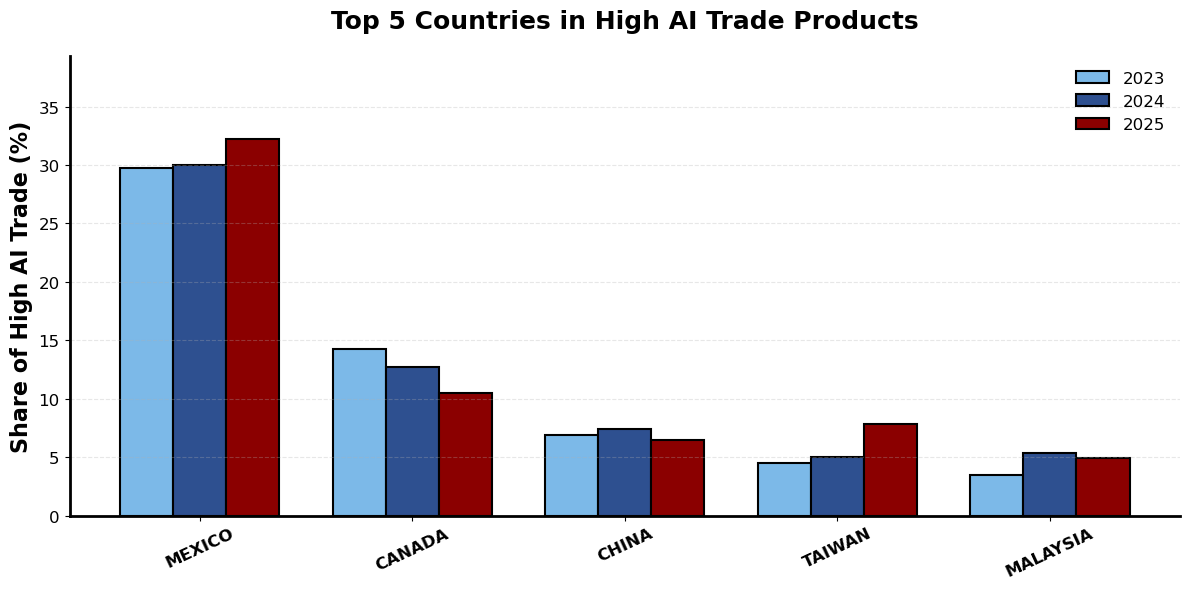

In [15]:
# Top 5 countries in High AI trade products, split by year (2023, 2024, 2025)

period_years = [2023, 2024, 2025]

country_high = dfcountry[
    (dfcountry['relevance'] == 'High') &
    (dfcountry['time'].dt.year.isin(period_years))
] .copy()

# Select top 5 countries based on combined 2024-2025 imports
country_exports_total = (
    country_high[country_high['time'].dt.year.isin([2024, 2025])]
    .groupby('CTY_NAME', observed=True)['exports']
    .sum()
    .sort_values(ascending=False)
)
top5_countries = country_exports_total.head(5).index.tolist()

# Compute yearly shares: country high-AI exports / total high-AI exports in that year
yearly_country_exports = (
    country_high[country_high['CTY_NAME'].isin(top5_countries)]
    .groupby(['CTY_NAME', country_high['time'].dt.year], observed=True)['exports']
    .sum()
    .unstack(fill_value=0)
    .reindex(columns=period_years, fill_value=0)
)

yearly_high_totals = (
    country_high.groupby(country_high['time'].dt.year, observed=True)['exports']
    .sum()
)

plot_df = pd.DataFrame({
    '2023': (yearly_country_exports[2023] / yearly_high_totals.loc[2023]) * 100,
    '2024': (yearly_country_exports[2024] / yearly_high_totals.loc[2024]) * 100,
    '2025': (yearly_country_exports[2025] / yearly_high_totals.loc[2025]) * 100
}).loc[top5_countries]

# Plot grouped bars
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(plot_df.index))
width = 0.25

bars_2023 = ax.bar(
    x - width,
    plot_df['2023'].values,
    width,
    label='2023',
    color='#7CB9E8',
    edgecolor='black',
    linewidth=1.5
)

bars_2024 = ax.bar(
    x,
    plot_df['2024'].values,
    width,
    label='2024',
    color='#2E5090',
    edgecolor='black',
    linewidth=1.5
)

bars_2025 = ax.bar(
    x + width,
    plot_df['2025'].values,
    width,
    label='2025',
    color='#8B0000',
    edgecolor='black',
    linewidth=1.5
)

# Formatting (consistent with existing style)
ax.set_ylabel('Share of High AI Trade (%)', fontsize=16, fontweight='bold')
ax.set_title('Top 5 Countries in High AI Trade Products', fontsize=18, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(plot_df.index)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.set_ylim(0, max(plot_df['2023'].max(), plot_df['2024'].max(), plot_df['2025'].max()) * 1.22)

ax.tick_params(axis='x', labelsize=12, rotation=25)
ax.tick_params(axis='y', labelsize=12)
for label in ax.get_xticklabels():
    label.set_fontweight('bold')

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.legend(fontsize=12, frameon=False, loc='upper right')



plt.tight_layout()
plt.show()


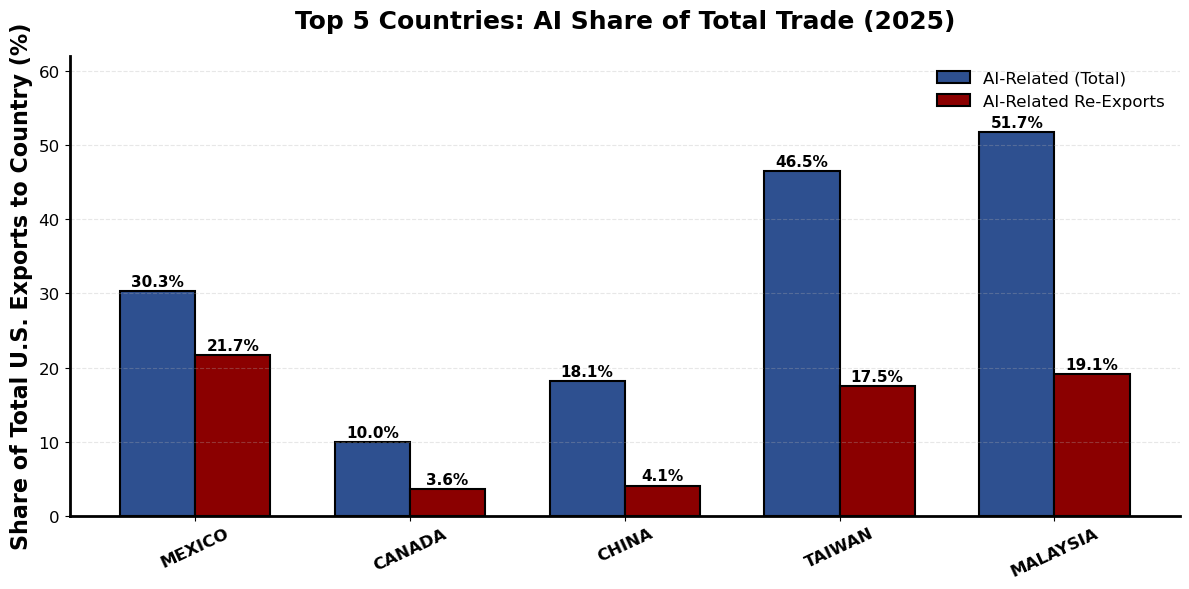


2025 AI share of total U.S. exports, by country:
  MEXICO: AI 30.3%  |  AI re-exports 21.7%  (re-exports = 72% of AI)
  CANADA: AI 10.0%  |  AI re-exports 3.6%  (re-exports = 36% of AI)
  CHINA: AI 18.1%  |  AI re-exports 4.1%  (re-exports = 22% of AI)
  TAIWAN: AI 46.5%  |  AI re-exports 17.5%  (re-exports = 38% of AI)
  MALAYSIA: AI 51.7%  |  AI re-exports 19.1%  (re-exports = 37% of AI)


In [16]:
# Country-level companion to the AI vs AI Re-Exports share chart above.
# For each top-5 country, show 2025 shares of total U.S. exports to that country:
#   - AI-Related (Total): AI-High Total Exports / All Total Exports
#   - AI-Related Re-Exports: AI-High Re-Exports / All Total Exports

dfctry_DF = pd.read_parquet(os.path.join(DF_DIR, 'All-country-exports-DF.parquet'))

dfctry_DF.rename(columns={'E_COMMODITY': 'HS10'}, inplace=True)
dfctry_DF["HS10"] = dfctry_DF["HS10"].astype(str).str.zfill(10)
dfctry_DF["HS2"]  = dfctry_DF["HS10"].str[0:2]
dfctry_DF["HS10"] = dfctry_DF["HS10"].astype('int64')
dfctry_DF["time"] = pd.to_datetime(dfctry_DF["time"], format="%Y-%m")
dfctry_DF["exports"] = dfctry_DF["ALL_VAL_MO"].astype(float)

# Same exclusions as the country chart above
dfctry_DF = dfctry_DF[~dfctry_DF["HS2"].isin(excluded_hs2)]
dfctry_DF = dfctry_DF[~dfctry_DF["CTY_NAME"].isin(excluded_cntry)]
dfctry_DF = dfctry_DF.merge(matlist[['HS10', 'relevance', 'primary_category']], on='HS10', how='left')

# 2025 only, top-5 countries (top5_countries from the cell above)
df_2025 = dfctry_DF[(dfctry_DF['time'].dt.year == 2025) &
                    (dfctry_DF['CTY_NAME'].isin(top5_countries))]

# Numerator: AI-High totals by export_type
ai_high_2025 = (df_2025[df_2025['relevance'] == 'High']
                .groupby(['CTY_NAME', 'export_type'], observed=True)['exports']
                .sum()
                .unstack(fill_value=0))

# Denominator: total US exports to country (all relevance), using Total Exports rows only
country_total_trade = (df_2025[df_2025['export_type'] == 'Total Exports']
                       .groupby('CTY_NAME', observed=True)['exports']
                       .sum())

# Shares
ai_total_share = (ai_high_2025['Total Exports'] / country_total_trade).reindex(top5_countries) * 100
ai_reexp_share = (ai_high_2025['Re-Exports']    / country_total_trade).reindex(top5_countries) * 100

# Plot
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(top5_countries))
width = 0.35

bars_total = ax.bar(
    x - width/2, ai_total_share.values, width,
    color='#2E5090', edgecolor='black', linewidth=1.5,
    label='AI-Related (Total)'
)
bars_re = ax.bar(
    x + width/2, ai_reexp_share.values, width,
    color='#8B0000', edgecolor='black', linewidth=1.5,
    label='AI-Related Re-Exports'
)

# Value labels in %
for bars in [bars_total, bars_re]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.3,
                f'{h:.1f}%',
                ha='center', va='bottom', fontsize=11, fontweight='bold')

# Formatting
ax.set_ylabel('Share of Total U.S. Exports to Country (%)', fontsize=16, fontweight='bold')
ax.set_title('Top 5 Countries: AI Share of Total Trade (2025)',
             fontsize=18, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(top5_countries)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.set_ylim(0, ai_total_share.max() * 1.20)

ax.tick_params(axis='x', labelsize=12, rotation=25)
ax.tick_params(axis='y', labelsize=12)
for label in ax.get_xticklabels():
    label.set_fontweight('bold')

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.legend(fontsize=12, frameon=False, loc='upper right')

plt.tight_layout()
plt.savefig(figfile + 'ai-exports-by-country-DF.png', bbox_inches='tight')
plt.savefig(figfile + 'ai-exports-by-country-DF.pdf', bbox_inches='tight')
plt.show()

print("\n2025 AI share of total U.S. exports, by country:")
for c in top5_countries:
    tot_share = ai_total_share.loc[c]
    re_share  = ai_reexp_share.loc[c]
    re_of_ai  = 100 * re_share / tot_share if tot_share > 0 else 0
    print(f"  {c}: AI {tot_share:.1f}%  |  AI re-exports {re_share:.1f}%  "
          f"(re-exports = {re_of_ai:.0f}% of AI)")


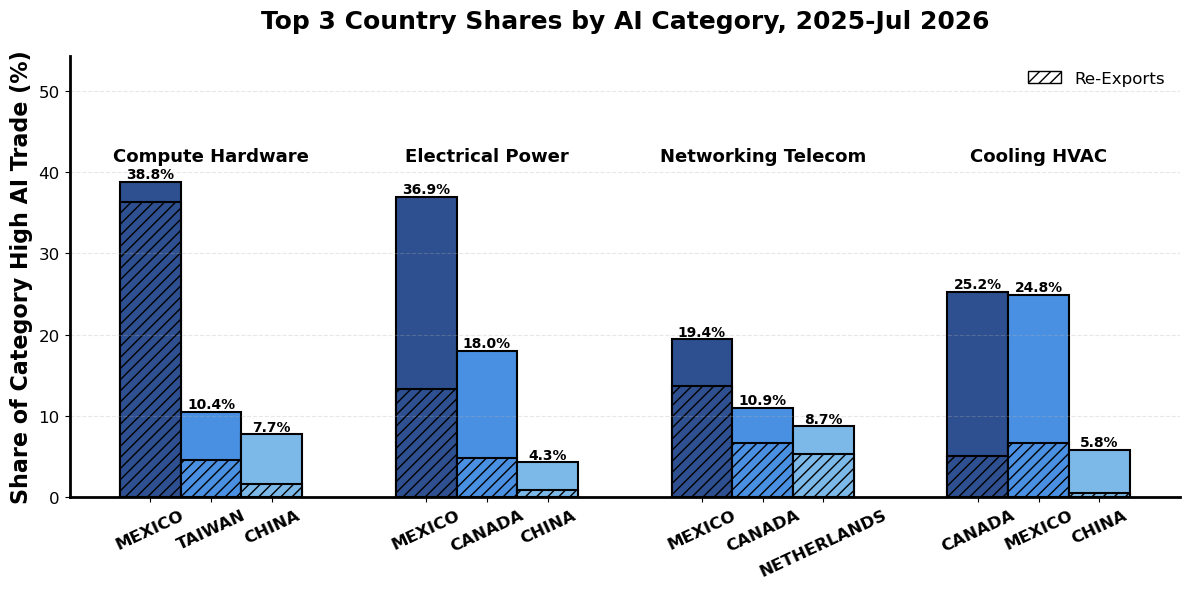


Top 3 country shares within each category (2025-Jul 2026):
  Compute Hardware:
    1) MEXICO: total 38.8%  |  re-exports 36.2%  (94% of total)
    2) TAIWAN: total 10.4%  |  re-exports 4.5%  (43% of total)
    3) CHINA: total 7.7%  |  re-exports 1.6%  (21% of total)
  Electrical Power:
    1) MEXICO: total 36.9%  |  re-exports 13.2%  (36% of total)
    2) CANADA: total 18.0%  |  re-exports 4.8%  (27% of total)
    3) CHINA: total 4.3%  |  re-exports 0.8%  (19% of total)
  Networking Telecom:
    1) MEXICO: total 19.4%  |  re-exports 13.6%  (70% of total)
    2) CANADA: total 10.9%  |  re-exports 6.6%  (61% of total)
    3) NETHERLANDS: total 8.7%  |  re-exports 5.3%  (60% of total)
  Cooling HVAC:
    1) CANADA: total 25.2%  |  re-exports 5.0%  (20% of total)
    2) MEXICO: total 24.8%  |  re-exports 6.7%  (27% of total)
    3) CHINA: total 5.8%  |  re-exports 0.5%  (9% of total)


In [17]:
# Top 3 country shares within each top AI category (two most recent years in the data; current year may be partial)
# Hatched portion of each bar shows the share that is re-exports (rest = domestic).

from matplotlib.patches import Patch

last_month = dfctry_DF['time'].max()
period_years = [last_month.year - 1, last_month.year]
period_label = (f"{period_years[0]}-{last_month:%b %Y}" if last_month.month < 12
                else f"{period_years[0]}-{period_years[1]}")
category_list = ['Compute_Hardware', 'Electrical_Power', 'Networking_Telecom', 'Cooling_HVAC']

# Use the DF country data (loaded above) so we can split Total vs Re-Exports
cat_country_DF = dfctry_DF[
    (dfctry_DF['relevance'] == 'High') &
    (dfctry_DF['primary_category'].isin(category_list)) &
    (dfctry_DF['time'].dt.year.isin(period_years))
].copy()

share_total_by_rank = {'Top 1': [], 'Top 2': [], 'Top 3': []}
share_re_by_rank    = {'Top 1': [], 'Top 2': [], 'Top 3': []}
country_names_by_cat = {}

for category in category_list:
    cat_data = cat_country_DF[cat_country_DF['primary_category'] == category]
    by_cty = (cat_data.groupby(['CTY_NAME', 'export_type'], observed=True)['exports']
              .sum()
              .unstack(fill_value=0))

    category_total = by_cty['Total Exports'].sum()
    top3 = by_cty.sort_values('Total Exports', ascending=False).head(3)

    top3_names = top3.index.tolist()
    top3_total = (top3['Total Exports'] / category_total * 100).tolist()
    top3_reexp = (top3.get('Re-Exports', pd.Series(0, index=top3.index)) / category_total * 100).tolist()

    while len(top3_total) < 3:
        top3_total.append(0.0)
        top3_reexp.append(0.0)
        top3_names.append('N/A')

    for i, key in enumerate(['Top 1', 'Top 2', 'Top 3']):
        share_total_by_rank[key].append(top3_total[i])
        share_re_by_rank[key].append(top3_reexp[i])
    country_names_by_cat[category] = top3_names

# Plot grouped bars
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(category_list))
width = 0.22

colors  = {'Top 1': '#2E5090', 'Top 2': '#4A90E2', 'Top 3': '#7CB9E8'}
offsets = {'Top 1': -width,    'Top 2': 0,         'Top 3': width}

for rank in ['Top 1', 'Top 2', 'Top 3']:
    bar_x = x + offsets[rank]
    # Solid total-share bar
    ax.bar(bar_x, share_total_by_rank[rank], width,
           color=colors[rank], edgecolor='black', linewidth=1.5)
    # Hatched overlay = re-export portion (from 0 up to re-export share)
    ax.bar(bar_x, share_re_by_rank[rank], width,
           color=colors[rank], edgecolor='black', linewidth=1.5,
           hatch='///')

# Total-share labels on top of each bar
for rank in ['Top 1', 'Top 2', 'Top 3']:
    for i, share in enumerate(share_total_by_rank[rank]):
        ax.text(x[i] + offsets[rank], share + 0.1,
                f'{share:.1f}%',
                ha='center', va='bottom', fontsize=10, fontweight='bold')

# Country labels under each bar
bar_positions = []
bar_labels = []
for idx, category in enumerate(category_list):
    c1, c2, c3 = country_names_by_cat[category]
    bar_positions.extend([x[idx] - width, x[idx], x[idx] + width])
    bar_labels.extend([c1, c2, c3])

ax.set_xticks(bar_positions)
ax.set_xticklabels(bar_labels)

# Category annotations centered on each group
max_total = max(max(share_total_by_rank['Top 1']),
                max(share_total_by_rank['Top 2']),
                max(share_total_by_rank['Top 3']))
category_label_y = 42
top_ylim = max(max_total * 1.40, 50)

for idx, category in enumerate(category_list):
    ax.text(x[idx], category_label_y, category.replace('_', ' '),
            ha='center', va='center', fontsize=13, fontweight='bold')

# Formatting (consistent style)
ax.set_ylabel('Share of Category High AI Trade (%)', fontsize=16, fontweight='bold')
ax.set_title(f'Top 3 Country Shares by AI Category, {period_label}', fontsize=18, fontweight='bold', pad=20)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.set_ylim(0, top_ylim)

ax.tick_params(axis='x', labelsize=12, rotation=25)
ax.tick_params(axis='y', labelsize=12)
for label in ax.get_xticklabels():
    label.set_fontweight('bold')

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)

# Legend: just the Re-Exports hatched indicator, in clear space above the category labels
ax.legend(
    handles=[Patch(facecolor='white', edgecolor='black', hatch='///', label='Re-Exports')],
    fontsize=12, frameon=False, loc='upper right'
)

plt.tight_layout()
plt.savefig(figfile + 'ai-exports-by-country-category.png', bbox_inches='tight')
plt.savefig(figfile + 'ai-exports-by-country-category.pdf', bbox_inches='tight')
plt.show()

print('\nTop 3 country shares within each category (' + period_label + '):')
for i, category in enumerate(category_list):
    print(f"  {category.replace('_', ' ')}:")
    for j, rank in enumerate(['Top 1', 'Top 2', 'Top 3']):
        c   = country_names_by_cat[category][j]
        tot = share_total_by_rank[rank][i]
        re  = share_re_by_rank[rank][i]
        re_of_tot = 100 * re / tot if tot > 0 else 0
        print(f"    {j+1}) {c}: total {tot:.1f}%  |  re-exports {re:.1f}%  ({re_of_tot:.0f}% of total)")


In [18]:
# -- Export-section LaTeX macros ----------------------------------------------
# Appends macros for the exports section to ai-trade-results.tex.
# Depends on variables from earlier cells:
#   plot_df              (country shares of AI-High exports, 2025 column)
#   grp_DF_high          (AI-High exports split by export_type: Total/Domestic/Re-Exports)
#   dfctry_DF            (country-level DF data with relevance + primary_category)
#   country_names_by_cat (top-3 country names per category)
#   share_total_by_rank  (top-3 country shares per category)

# --- 1. Mexico share of total AI-High exports in 2025 ---
mexico_ai_share_2025 = plot_df.loc['MEXICO', '2025']

# --- 2. Mexico share by category (from top-3 chart data) ---
cat_list = ['Compute_Hardware', 'Electrical_Power', 'Networking_Telecom', 'Cooling_HVAC']
mexico_cat_shares = {}
for i, cat in enumerate(cat_list):
    names = country_names_by_cat[cat]
    for j, rank in enumerate(['Top 1', 'Top 2', 'Top 3']):
        if names[j] == 'MEXICO':
            mexico_cat_shares[cat] = share_total_by_rank[rank][i]
            break
    if cat not in mexico_cat_shares:
        mexico_cat_shares[cat] = 0.0

# --- 3. Re-export share of AI-High exports (2025) ---
ai_total_2025_val = grp_DF_high['Total Exports'].loc['2025'].sum()
ai_reexp_2025_val = grp_DF_high['Re-Exports'].loc['2025'].sum()
ai_domestic_2025_val = grp_DF_high['Domestic Exports'].loc['2025'].sum()
ai_reexport_share_2025 = (ai_reexp_2025_val / ai_total_2025_val) * 100

# --- 4. Growth in domestic AI-High exports (2025 vs 2023) ---
ai_domestic_2023_val = grp_DF_high['Domestic Exports'].loc['2023'].sum()
domestic_ai_export_growth = ((ai_domestic_2025_val - ai_domestic_2023_val) / ai_domestic_2023_val) * 100

# --- 5. Mexico: re-export share of AI-High exports (2025) ---
mex_2025 = dfctry_DF[(dfctry_DF['CTY_NAME'] == 'MEXICO') &
                     (dfctry_DF['time'].dt.year == 2025) &
                     (dfctry_DF['relevance'] == 'High')]
mex_by_type = mex_2025.groupby('export_type', observed=True)['exports'].sum()
mex_ai_total = mex_by_type.get('Total Exports', 0)
mex_ai_reexp = mex_by_type.get('Re-Exports', 0)
mexico_ai_reexport_share = (mex_ai_reexp / mex_ai_total * 100) if mex_ai_total > 0 else 0

# --- 6. Mexico: re-export share of Compute Hardware exports (2025) ---
mex_ch_2025 = dfctry_DF[(dfctry_DF['CTY_NAME'] == 'MEXICO') &
                        (dfctry_DF['time'].dt.year == 2025) &
                        (dfctry_DF['relevance'] == 'High') &
                        (dfctry_DF['primary_category'] == 'Compute_Hardware')]
mex_ch_by_type = mex_ch_2025.groupby('export_type', observed=True)['exports'].sum()
mex_ch_total = mex_ch_by_type.get('Total Exports', 0)
mex_ch_reexp = mex_ch_by_type.get('Re-Exports', 0)
mexico_compute_reexport_share = (mex_ch_reexp / mex_ch_total * 100) if mex_ch_total > 0 else 0

# --- Write all macros ---
with open(texfile, 'a') as f:
    f.write(f'% -- Export section macros --\n')
    f.write(f'\\def\\mexicoAiExportShare{{{mexico_ai_share_2025:.0f}}} % Mexico share of AI-High exports 2025\n')
    f.write(f'\\def\\mexicoComputeExportShare{{{mexico_cat_shares["Compute_Hardware"]:.0f}}} % Mexico share of Compute Hardware exports\n')
    f.write(f'\\def\\mexicoElectricalExportShare{{{mexico_cat_shares["Electrical_Power"]:.0f}}} % Mexico share of Electrical Power exports\n')
    f.write(f'\\def\\mexicoNetworkingExportShare{{{mexico_cat_shares["Networking_Telecom"]:.0f}}} % Mexico share of Networking Telecom exports\n')
    f.write(f'\\def\\mexicoCoolingExportShare{{{mexico_cat_shares["Cooling_HVAC"]:.0f}}} % Mexico share of Cooling HVAC exports\n')
    f.write(f'\\def\\aiReexportShare{{{ai_reexport_share_2025:.0f}}} % Re-export share of AI-High exports 2025\n')
    f.write(f'\\def\\domesticAiExportGrowth{{{domestic_ai_export_growth:.1f}}} % Domestic AI export growth 2025 vs 2023\n')
    f.write(f'\\def\\mexicoAiReexportShare{{{mexico_ai_reexport_share:.0f}}} % Mexico re-export share of AI exports 2025\n')
    f.write(f'\\def\\mexicoComputeReexportShare{{{mexico_compute_reexport_share:.0f}}} % Mexico re-export share of Compute HW exports 2025\n')

print("Appended export-section macros to", texfile)
print(f"  Mexico AI export share (2025):        {mexico_ai_share_2025:.1f}%")
print(f"  Mexico Compute HW share:              {mexico_cat_shares['Compute_Hardware']:.1f}%")
print(f"  Mexico Electrical Power share:         {mexico_cat_shares['Electrical_Power']:.1f}%")
print(f"  Mexico Networking Telecom share:       {mexico_cat_shares['Networking_Telecom']:.1f}%")
print(f"  Mexico Cooling HVAC share:             {mexico_cat_shares['Cooling_HVAC']:.1f}%")
print(f"  AI re-export share (2025):             {ai_reexport_share_2025:.1f}%")
print(f"  Domestic AI export growth (25 vs 23):  {domestic_ai_export_growth:.1f}%")
print(f"  Mexico AI re-export share:             {mexico_ai_reexport_share:.1f}%")
print(f"  Mexico Compute HW re-export share:     {mexico_compute_reexport_share:.1f}%")


Appended export-section macros to ../paper/tables/ai-trade-results.tex
  Mexico AI export share (2025):        32.3%
  Mexico Compute HW share:              38.8%
  Mexico Electrical Power share:         36.9%
  Mexico Networking Telecom share:       19.4%
  Mexico Cooling HVAC share:             24.8%
  AI re-export share (2025):             46.4%
  Domestic AI export growth (25 vs 23):  23.1%
  Mexico AI re-export share:             71.7%
  Mexico Compute HW re-export share:     92.4%
